# 01: Respiratory rate from a clinical signal (BIDMC)

Estimate breathing rate from the impedance respiration signal of the BIDMC PPG and Respiration Dataset (Pimentel et al. 2017) and score it against manual breath annotations from two annotators.

- 53 recordings, 8 min each, 125 Hz
- Pipeline: detrend -> bandpass (0.1-0.7 Hz) -> 30 s sliding window, 5 s step -> Welch peak (and a peak-detection comparison)
- Reference: in each window, 60 / median inter-breath interval of annotated breaths, averaged over the two annotators (windows with fewer than 3 annotated breaths from both are skipped)

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, wfdb, matplotlib.pyplot as plt
from breathcam.signal import welch_rate, peak_rate
from breathcam.eval import mae, rmse, within, bland_altman, plot_bland_altman

DATA, W, S = "../data/bidmc", 30, 5

In [2]:
rows = []
for i in range(1, 54):
    name = f"{DATA}/bidmc{i:02d}"
    rec = wfdb.rdrecord(name); fs = rec.fs
    x = rec.p_signal[:, 0]                     # RESP (impedance)
    ann = wfdb.rdann(name, "breath")
    t_ann = [ann.sample[np.array(ann.aux_note) == a] / fs for a in ("ann1", "ann2")]
    t0, wr, q = welch_rate(x, fs, W, S)
    for k, t in enumerate(t0):
        refs = []
        for ta in t_ann:
            b = ta[(ta >= t) & (ta < t + W)]
            if len(b) >= 3:
                refs.append(60 / np.median(np.diff(b)))
        if not refs:
            continue
        seg = x[int(t * fs):int((t + W) * fs)]
        rows.append(dict(rec=i, t=t, ref=np.mean(refs), welch=wr[k], peaks=peak_rate(seg, fs)[0], quality=q[k]))
df = pd.DataFrame(rows)
print(len(df), "windows from", df.rec.nunique(), "recordings")
print(f"reference range: {df.ref.min():.1f} - {df.ref.max():.1f} breaths/min")

4809 windows from 53 recordings
reference range: 4.6 - 28.3 breaths/min


In [3]:
table = pd.DataFrame({
    m: dict(MAE=mae(df[m], df.ref), RMSE=rmse(df[m], df.ref), within_2bpm=within(df[m], df.ref),
            bias=bland_altman(df[m], df.ref)[2])
    for m in ("welch", "peaks")}).T.round(2)
table

,MAE,RMSE,within_2bpm,bias
welch,1.16,2.84,0.89,0.03
peaks,1.62,3.79,0.84,1.26


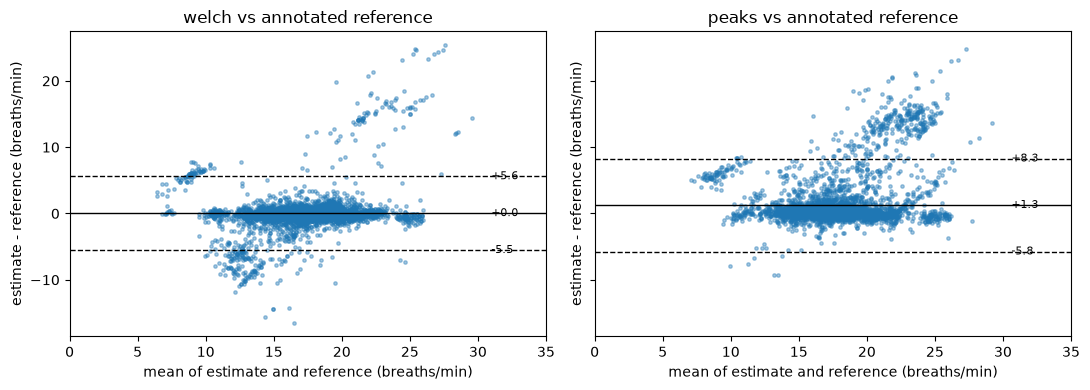

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, m in zip(axes, ("welch", "peaks")):
    plot_bland_altman(df[m], df.ref, ax, title=f"{m} vs annotated reference")
    ax.set_xlim(0, 35)
plt.tight_layout()
plt.savefig("../docs/figures/bidmc_bland_altman.png", dpi=150)

In [5]:
# Where do Welch and peak detection disagree, and does the quality score flag it?
df["gap"] = (df.welch - df.peaks).abs()
df["q_bin"] = pd.qcut(df.quality, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
df.groupby("q_bin", observed=True).apply(
    lambda g: pd.Series(dict(n=len(g), welch_MAE=mae(g.welch, g.ref), peaks_MAE=mae(g.peaks, g.ref),
                             welch_peaks_gap=g.gap.mean())), include_groups=False).round(2)

,n,welch_MAE,peaks_MAE,welch_peaks_gap
q_bin,,,,
Q1 low,1203.0,3.15,4.41,4.84
Q2,1202.0,0.80,1.37,1.57
Q3,1202.0,0.38,0.42,0.49
Q4 high,1202.0,0.30,0.27,0.24


In [6]:
# Worst recordings by Welch MAE
df.groupby("rec").apply(lambda g: mae(g.welch, g.ref), include_groups=False).sort_values(ascending=False).head(5).round(2)

rec
39    7.48
5     4.83
46    4.81
2     4.54
23    3.49
dtype: float64

## Notes

Fill in after reading the output above: headline MAE, where Welch and peaks disagree, whether low-quality windows carry most of the error, and what the worst recordings look like. Caveat: the reference is derived from the same impedance signal the algorithm sees, so this measures agreement with manual annotation of that signal, not agreement with an independent sensor.